In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pylab as plt

In [2]:
rides = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\Mariam_Work\rideBookings.csv")
rides.head().T

,0,1,2,3,4
Date,2024-03-23,2024-11-29,2024-08-23,2024-10-21,2024-09-16
Time,12:29:38,18:01:39,08:56:10,17:17:25,22:08:00
Booking ID,"""CNR5884300""","""CNR1326809""","""CNR8494506""","""CNR8906825""","""CNR1950162"""
Booking Status,No Driver Found,Incomplete,Completed,Completed,Completed
Customer ID,"""CID1982111""","""CID4604802""","""CID9202816""","""CID2610914""","""CID9933542"""
Vehicle Type,eBike,Go Sedan,Auto,Premier Sedan,Bike
Pickup Location,Palam Vihar,Shastri Nagar,Khandsa,Central Secretariat,Ghitorni Village
Drop Location,Jhilmil,Gurgaon Sector 56,Malviya Nagar,Inderlok,Khan Market
Avg VTAT,NaN,4.9,13.4,13.1,5.3
Avg CTAT,NaN,14.0,25.8,28.5,19.6


In [3]:
print(f"The shape of the dataset is {rides.shape}")
for cols in rides.columns:
    print(f"Column: {cols:35} || type: {str(rides[cols].dtype):7} || missing values : {round(rides[cols].isna().sum()/ rides.shape[0]*100,2)}%")

The shape of the dataset is (150000, 21)
Column: Date                                || type: str     || missing values : 0.0%
Column: Time                                || type: str     || missing values : 0.0%
Column: Booking ID                          || type: str     || missing values : 0.0%
Column: Booking Status                      || type: str     || missing values : 0.0%
Column: Customer ID                         || type: str     || missing values : 0.0%
Column: Vehicle Type                        || type: str     || missing values : 0.0%
Column: Pickup Location                     || type: str     || missing values : 0.0%
Column: Drop Location                       || type: str     || missing values : 0.0%
Column: Avg VTAT                            || type: float64 || missing values : 7.0%
Column: Avg CTAT                            || type: float64 || missing values : 32.0%
Column: Cancelled Rides by Customer         || type: float64 || missing values : 93.0%
Column: Rea

In [4]:
rides_copy = rides.copy()

In [5]:
# fill missing values before data type conversion
rides_copy['Cancelled Rides by Customer'] = rides_copy['Cancelled Rides by Customer'].astype('Int64')
rides_copy['Cancelled Rides by Driver'] = rides_copy['Cancelled Rides by Driver'].astype('Int64')
rides_copy['Incomplete Rides'] = rides_copy['Incomplete Rides'].astype('Int64')
rides_copy['Cancelled Rides by Customer'] = rides_copy['Cancelled Rides by Customer'].fillna(0)
rides_copy['Cancelled Rides by Driver'] = rides_copy['Cancelled Rides by Driver'].fillna(0)
rides_copy['Incomplete Rides'] = rides_copy['Incomplete Rides'].fillna(0)
rides_copy['Incomplete Rides Reason']= rides_copy['Incomplete Rides Reason'].fillna('Unknown', inplace=True)
rides_copy['Reason for cancelling by Customer']= rides_copy['Reason for cancelling by Customer'].fillna('Unknown', inplace=True)
rides_copy['Driver Cancellation Reason']= rides_copy['Driver Cancellation Reason'].fillna('Unknown', inplace=True)
rides_copy['Payment Method'] = rides_copy['Payment Method'].fillna('Unknown', inplace=True)

C:\Users\USER\AppData\Local\Temp\ipykernel_13500\3495062960.py:8: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  rides_copy['Incomplete Rides Reason']= rides_copy['Incomplete Rides Reason'].fillna('Unknown', inplace=True)
C:\Users\USER\AppData\Local\Temp\ipykernel_13500\3495062960.py:9: ChainedAssignmentError: A value is being set on 

In [6]:
rides_copy['Cancelled Rides by Customer'].unique()

<IntegerArray>
[0, 1]
Length: 2, dtype: Int64

In [7]:
# Mapping for float to str columns
Yes_No = {1 : 'Yes', 0:'No'}
rides_copy['Cancelled Rides by Customer'] = rides_copy['Cancelled Rides by Customer'].apply(lambda x:Yes_No[x])
rides_copy['Cancelled Rides by Driver'] = rides_copy['Cancelled Rides by Driver'].apply(lambda x:Yes_No[x])
rides_copy['Incomplete Rides'] = rides_copy['Incomplete Rides'].apply(lambda x:Yes_No[x])

In [8]:
rides_copy['Avg CTAT'] = rides_copy['Avg CTAT'].fillna(rides_copy['Avg CTAT'].mode()[0])
rides_copy['Avg VTAT'] = rides_copy['Avg VTAT'].fillna(rides_copy['Avg VTAT'].mean())
rides_copy['Booking Value'] = rides_copy['Booking Value'].fillna(rides_copy['Booking Value'].mode()[0])
rides_copy['Ride Distance'] = rides_copy['Ride Distance'].fillna(rides_copy['Ride Distance'].mean())
rides_copy['Customer Rating'] = rides_copy['Customer Rating'].fillna(rides_copy['Customer Rating'].mode()[0])
rides_copy['Driver Ratings'] = rides_copy['Driver Ratings'].fillna(rides_copy['Driver Ratings'].mean())
for cols in rides_copy.columns:
    print(f"Column: {cols:35} || type: {str(rides_copy[cols].dtype):7} || missing values : {round(rides_copy[cols].isna().sum()/ rides_copy.shape[0]*100,2)}%")

Column: Date                                || type: str     || missing values : 0.0%
Column: Time                                || type: str     || missing values : 0.0%
Column: Booking ID                          || type: str     || missing values : 0.0%
Column: Booking Status                      || type: str     || missing values : 0.0%
Column: Customer ID                         || type: str     || missing values : 0.0%
Column: Vehicle Type                        || type: str     || missing values : 0.0%
Column: Pickup Location                     || type: str     || missing values : 0.0%
Column: Drop Location                       || type: str     || missing values : 0.0%
Column: Avg VTAT                            || type: float64 || missing values : 0.0%
Column: Avg CTAT                            || type: float64 || missing values : 0.0%
Column: Cancelled Rides by Customer         || type: str     || missing values : 0.0%
Column: Reason for cancelling by Customer   || type: s

In [9]:
# Date Type conversion str - datetime[ns]
rides_copy['Date'] = pd.to_datetime(rides_copy['Date'])
rides_copy['Year'] = rides_copy['Date'].dt.year
rides_copy['Month_Name'] = rides_copy['Date'].dt.month_name()
rides_copy['Day_Name'] = rides_copy['Date'].dt.day_name()
weekend = ['Saturday', 'Sunday']
weekday = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
rides_copy['Is_Weekend'] = rides_copy['Day_Name'].isin(weekend) 
rides_copy['Hour'] = pd.to_datetime(rides_copy['Time'], format = '%H:%M:%S').dt.hour

In [10]:
from typing import List, Optional

def validate_data(original_df: pd.DataFrame, 
                  cleaned_df: pd.DataFrame,
                  date_columns: list = None,
                  critical_columns: list = None,
                  outlier_method: str = 'iqr',           # 'iqr' or 'zscore'
                  outlier_threshold: float = 1.5,        # 1.5 for IQR, 3 for z-score
                  outlier_action: str = 'report',        # 'report' | 'remove' | 'winsorize'
                  winsorize_limits: tuple = (0.01, 0.01),# used only when outlier_action='winsorize'
                  numerical_cols: list = None
                  ) -> pd.DataFrame:
    """
    Comprehensive data validation report comparing original vs cleaned dataset.
    Supports outlier detection with three actions: report, remove, or winsorize.
    
    Parameters
    ----------
    original_df : pd.DataFrame
        The raw / original dataset
    cleaned_df : pd.DataFrame
        The cleaned dataset
    date_columns : list, optional
        List of column names that should be datetime
    critical_columns : list, optional
        List of important columns for extra checks
    outlier_method : str
        'iqr' (default) or 'zscore'
    outlier_threshold : float
        1.5 for IQR (default), 3.0 recommended for z-score
    outlier_action : str
        'report'    → only show outlier statistics (default)
        'remove'    → drop rows that contain outliers
        'winsorize' → cap extreme values at the given percentiles
    winsorize_limits : tuple
        (lower_limit, upper_limit) used when outlier_action='winsorize'
        Example: (0.01, 0.01) → 1st and 99th percentile
    numerical_cols : list, optional
        Specific numerical columns to check. If None → auto-detect
    
    Returns
    -------
    pd.DataFrame
        The final cleaned DataFrame
    """
    
    print("=" * 70)
    print("📊 DATA VALIDATION REPORT")
    print("=" * 70)
    
    # -------------------------------------------------
    # 1. Shape comparison
    # -------------------------------------------------
    print("\n1. SHAPE COMPARISON")
    print("-" * 40)
    print(f"{'Metric':<25} {'Original':>15} {'Cleaned':>15} {'Change':>12}")
    print(f"{'Rows':<25} {original_df.shape[0]:>15,} {cleaned_df.shape[0]:>15,} "
          f"{cleaned_df.shape[0] - original_df.shape[0]:>+12,}")
    print(f"{'Columns':<25} {original_df.shape[1]:>15} {cleaned_df.shape[1]:>15} "
          f"{cleaned_df.shape[1] - original_df.shape[1]:>+12}")
    
    rows_dropped = original_df.shape[0] - cleaned_df.shape[0]
    pct_dropped = (rows_dropped / original_df.shape[0]) * 100 if original_df.shape[0] > 0 else 0
    print(f"\n→ Rows removed so far: {rows_dropped:,} ({pct_dropped:.2f}%)")
    
    # -------------------------------------------------
    # 2. Column changes
    # -------------------------------------------------
    print("\n2. COLUMN CHANGES")
    print("-" * 40)
    orig_cols = set(original_df.columns)
    clean_cols = set(cleaned_df.columns)
    
    dropped_cols = orig_cols - clean_cols
    added_cols = clean_cols - orig_cols
    
    if dropped_cols:
        print(f"Dropped columns ({len(dropped_cols)}): {sorted(dropped_cols)}")
    else:
        print("No columns were dropped.")
        
    if added_cols:
        print(f"Added columns   ({len(added_cols)}): {sorted(added_cols)}")
    else:
        print("No new columns were added.")
    
    # -------------------------------------------------
    # 3. Missing values comparison
    # -------------------------------------------------
    print("\n3. MISSING VALUES COMPARISON")
    print("-" * 40)
    
    orig_missing = original_df.isna().sum()
    clean_missing = cleaned_df.isna().sum()
    
    missing_summary = pd.DataFrame({
        'Original_Missing': orig_missing,
        'Cleaned_Missing': clean_missing
    }).fillna(0).astype(int)
    
    missing_summary = missing_summary[
        (missing_summary['Original_Missing'] > 0) | 
        (missing_summary['Cleaned_Missing'] > 0)
    ]
    
    if not missing_summary.empty:
        print(missing_summary.to_string())
    else:
        print("No missing values in either dataset.")
    
    # -------------------------------------------------
    # 4. Duplicates comparison
    # -------------------------------------------------
    print("\n4. DUPLICATES COMPARISON")
    print("-" * 40)
    orig_dups = original_df.duplicated().sum()
    clean_dups = cleaned_df.duplicated().sum()
    print(f"Original duplicates : {orig_dups:,}")
    print(f"Cleaned duplicates  : {clean_dups:,}")
    
    # -------------------------------------------------
    # 5. Data Type Validation
    # -------------------------------------------------
    print("\n5. DATA TYPE VALIDATION")
    print("-" * 40)
    
    common_cols = list(orig_cols & clean_cols)
    
    type_changes = []
    for col in common_cols:
        orig_dtype = str(original_df[col].dtype)
        clean_dtype = str(cleaned_df[col].dtype)
        if orig_dtype != clean_dtype:
            type_changes.append({
                'Column': col,
                'Original Type': orig_dtype,
                'Cleaned Type': clean_dtype
            })
    
    if type_changes:
        print(pd.DataFrame(type_changes).to_string(index=False))
    else:
        print("No data type changes detected in common columns.")
    
    # -------------------------------------------------
    # 6. Date Validation
    # -------------------------------------------------
    print("\n6. DATE VALIDATION")
    print("-" * 40)
    
    if date_columns is None:
        date_columns = [col for col in cleaned_df.columns 
                        if 'date' in col.lower() or 'time' in col.lower()]
    
    if not date_columns:
        print("No date columns specified or detected.")
    else:
        for col in date_columns:
            if col not in cleaned_df.columns:
                print(f"⚠️  Column '{col}' not found in cleaned dataset.")
                continue
                
            print(f"\n→ Column: {col}")
            series = cleaned_df[col]
            
            if not pd.api.types.is_datetime64_any_dtype(series):
                print(f"   Status: Not datetime type (current type: {series.dtype})")
                continue
                
            print(f"   Min date     : {series.min()}")
            print(f"   Max date     : {series.max()}")
            print(f"   Null dates   : {series.isna().sum()}")
            
            future = series[series > pd.Timestamp.today()]
            if len(future) > 0:
                print(f"   ⚠️  Future dates found: {len(future)}")
    
    # -------------------------------------------------
    # 7. OUTLIER DETECTION + ACTION (report / remove / winsorize)
    # -------------------------------------------------
    print("\n7. OUTLIER DETECTION & HANDLING")
    print("-" * 40)
    
    if numerical_cols is None:
        numerical_cols = cleaned_df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numerical_cols:
        print("No numerical columns found for outlier detection.")
        return cleaned_df
    
    print(f"Method used          : {outlier_method.upper()}")
    print(f"Threshold            : {outlier_threshold}")
    print(f"Action               : {outlier_action.upper()}")
    if outlier_action == 'winsorize':
        print(f"Winsorize limits     : {winsorize_limits}")
    print(f"Columns being checked: {numerical_cols}\n")
    
    outlier_report = []
    outlier_mask = pd.Series(False, index=cleaned_df.index)
    
    # We will work on a copy so we can safely modify values
    result_df = cleaned_df.copy()
    
    for col in numerical_cols:
        series = result_df[col].dropna()
        
        if outlier_method.lower() == 'iqr':
            Q1 = series.quantile(0.25)
            Q3 = series.quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - outlier_threshold * IQR
            upper = Q3 + outlier_threshold * IQR
        else:  # zscore
            mean = series.mean()
            std = series.std()
            lower = mean - outlier_threshold * std
            upper = mean + outlier_threshold * std
        
        # Detect outliers
        col_outliers = (result_df[col] < lower) | (result_df[col] > upper)
        n_outliers = col_outliers.sum()
        
        outlier_report.append({
            'Column': col,
            'Lower Bound': round(lower, 2),
            'Upper Bound': round(upper, 2),
            'Outliers': int(n_outliers),
            'Percentage': round(n_outliers / len(result_df) * 100, 2)
        })
        
        outlier_mask = outlier_mask | col_outliers
        
        # ----- Winsorize action -----
        if outlier_action == 'winsorize':
            lower_limit = result_df[col].quantile(winsorize_limits[0])
            upper_limit = result_df[col].quantile(1 - winsorize_limits[1])
            
            result_df[col] = result_df[col].clip(lower=lower_limit, upper=upper_limit)
    
    # Display report
    report_df = pd.DataFrame(outlier_report)
    print(report_df.to_string(index=False))
    
    total_outlier_rows = outlier_mask.sum()
    print(f"\n→ Total rows containing at least one outlier: {total_outlier_rows:,} "
          f"({total_outlier_rows / len(cleaned_df) * 100:.2f}%)")
    
    # ----- Apply remove action -----
    if outlier_action == 'remove' and total_outlier_rows > 0:
        result_df = result_df[~outlier_mask].copy()
        print(f"\n✅ Outliers removed. New shape: {result_df.shape}")
        
    elif outlier_action == 'winsorize':
        print(f"\n✅ Winsorization applied using limits {winsorize_limits}")
        print(f"   (Values below {winsorize_limits[0]*100:.1f}th percentile and "
              f"above {(1-winsorize_limits[1])*100:.1f}th percentile were capped)")
        
    elif outlier_action == 'report':
        print("\nℹ️  Outliers detected but no action taken "
              "(use outlier_action='remove' or 'winsorize').")
    
    # -------------------------------------------------
    # 8. Critical Columns Quick Check
    # -------------------------------------------------
    if critical_columns:
        print("\n8. CRITICAL COLUMNS CHECK")
        print("-" * 40)
        for col in critical_columns:
            if col in result_df.columns:
                nulls = result_df[col].isna().sum()
                print(f"{col:<30} → Nulls: {nulls} | Unique: {result_df[col].nunique()}")
            else:
                print(f"{col:<30} → ⚠️ Column not found")
    
    # -------------------------------------------------
    # Final Summary
    # -------------------------------------------------
    print("\n" + "=" * 70)
    print("✅ VALIDATION COMPLETE")
    print("=" * 70)
    print(f"Final dataset shape: {result_df.shape[0]:,} rows × {result_df.shape[1]} columns")
    
    return result_df
            

In [11]:
rides_final = validate_data(
    rides, rides_copy,
    outlier_action='winsorize',
    winsorize_limits=(0.01, 0.01),   # 1st – 99th percentile
    numerical_cols=['Avg CTAT', 'Avg VTAT']
)

📊 DATA VALIDATION REPORT

1. SHAPE COMPARISON
----------------------------------------
Metric                           Original         Cleaned       Change
Rows                              150,000         150,000           +0
Columns                                21              26           +5

→ Rows removed so far: 0 (0.00%)

2. COLUMN CHANGES
----------------------------------------
No columns were dropped.
Added columns   (5): ['Day_Name', 'Hour', 'Is_Weekend', 'Month_Name', 'Year']

3. MISSING VALUES COMPARISON
----------------------------------------
                                   Original_Missing  Cleaned_Missing
Avg CTAT                                      48000                0
Avg VTAT                                      10500                0
Booking Value                                 48000                0
Cancelled Rides by Customer                  139500                0
Cancelled Rides by Driver                    123000                0
Customer Rating   

In [12]:
rides_final['Revenue_per_km'] = rides_final['Booking Value'] / rides_final['Ride Distance']
rides_copy['AVG_WaitTime'] = rides_final['Avg CTAT'] + rides_final['Avg VTAT']

In [13]:
# Time Values
def time_category(hour):
    if hour >=5 and hour < 12:
        return 'Morninig'
    elif hour >= 12 and hour < 17:
        return 'Afternoon'
    elif hour >=17 and hour < 21:
        return 'Evening'
    else:
        return 'Night'

rides_final['Time_of_day'] = rides_final['Hour'].apply(time_category)
rides_final[['Hour', 'Time_of_day']].head(5)

,Hour,Time_of_day
0,12,Afternoon
1,18,Evening
2,8,Morninig
3,17,Evening
4,22,Night


In [14]:
def season_of_year(month):
    if month in ['March', 'April', 'May']:
        return 'Spring'
    elif month in ['June', 'July','August']:
        return 'Summer'
    elif month in ['September','October', "November"]:
        return 'Fall (Autumn)'
    else:
        return 'Winter'

rides_final['Season'] = rides_final['Month_Name'].apply(season_of_year)
rides_final[['Month_Name','Season']].head()


,Month_Name,Season
0,March,Spring
1,November,Fall (Autumn)
2,August,Summer
3,October,Fall (Autumn)
4,September,Fall (Autumn)


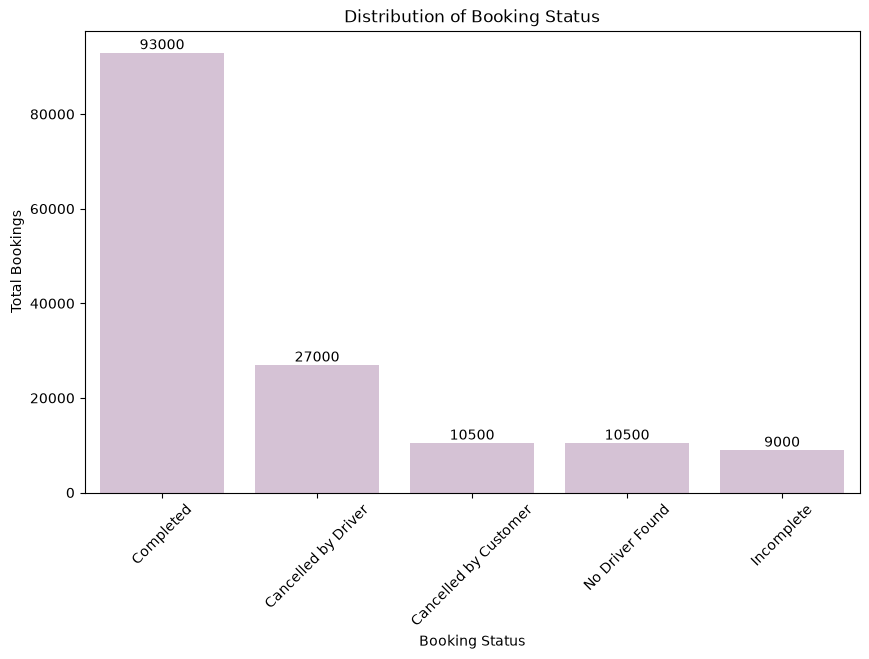

In [15]:
# Distribution of Booking Status
booking_status = rides_final.groupby('Booking Status')['Booking ID'].size().reset_index(name='Count').sort_values(by='Count', ascending=False)
fig,ax = plt.subplots(figsize = (10,6))
sns.barplot(x = 'Booking Status', y='Count', data=booking_status, color='thistle', ax =ax)
ax.set_title("Distribution of Booking Status")
ax.set(xlabel = 'Booking Status', ylabel ='Total Bookings')
ax.tick_params(axis ='x', rotation = 45)
for bars in ax.containers:
    ax.bar_label(bars, label_type='edge')
plt.show()

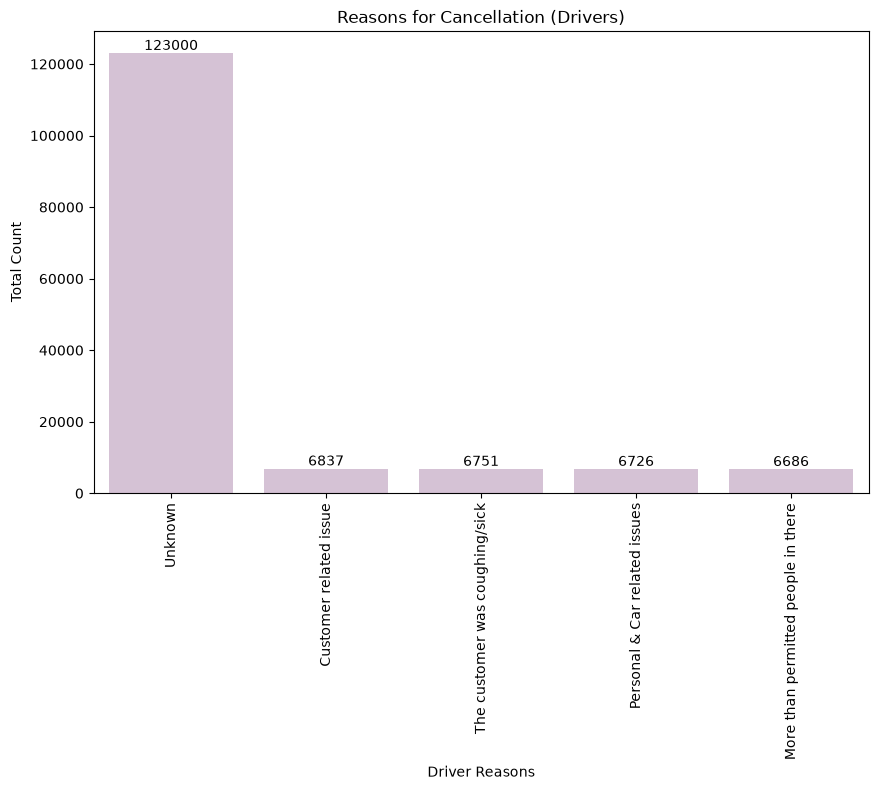

In [16]:
# Reasons for Cancellation (Drivers)
cancellation_reasons = rides_final.groupby('Driver Cancellation Reason')['Booking ID'].size().reset_index(name='Total Count').sort_values(by = 'Total Count', ascending=False)
fig,ax = plt.subplots(figsize = (10,6))
sns.barplot(x = 'Driver Cancellation Reason', y='Total Count', data=cancellation_reasons, color='thistle', ax =ax)
ax.set_title("Reasons for Cancellation (Drivers)")
ax.set(xlabel = 'Driver Reasons', ylabel ='Total Count')
ax.tick_params(axis ='x', rotation = 90)
for bars in ax.containers:
    ax.bar_label(bars, label_type='edge')
plt.show()

In [17]:
# Most Booked Routes
booked_routes = rides_final.groupby(['Pickup Location', 'Drop Location'])['Booking ID'].size().reset_index(name='Total Bookings').sort_values(by='Total Bookings', ascending=False)
booked_routes.rename(columns={'Pickup Location' : 'Pickup_Location', 'Drop Location': 'Drop_Location', 'Total Bookings':'Total_Bookings'}, inplace=True)
print("The most booked routes are:")
for rows in booked_routes.head(10).itertuples():
    print(f"{rows.Pickup_Location} ----> {rows.Drop_Location} : {rows.Total_Bookings}")


The most booked routes are:
DLF City Court ----> Bhiwadi : 17
Akshardham ----> RK Puram : 16
Janakpuri ----> Faridabad Sector 15 : 16
Vatika Chowk ----> Rithala : 15
Rithala ----> Udyog Vihar Phase 4 : 15
Jor Bagh ----> Rohini East : 15
Ghaziabad ----> Badshahpur : 15
Kashmere Gate ISBT ----> Tilak Nagar : 14
Chirag Delhi ----> Noida Film City : 14
Subhash Nagar ----> Basai Dhankot : 14


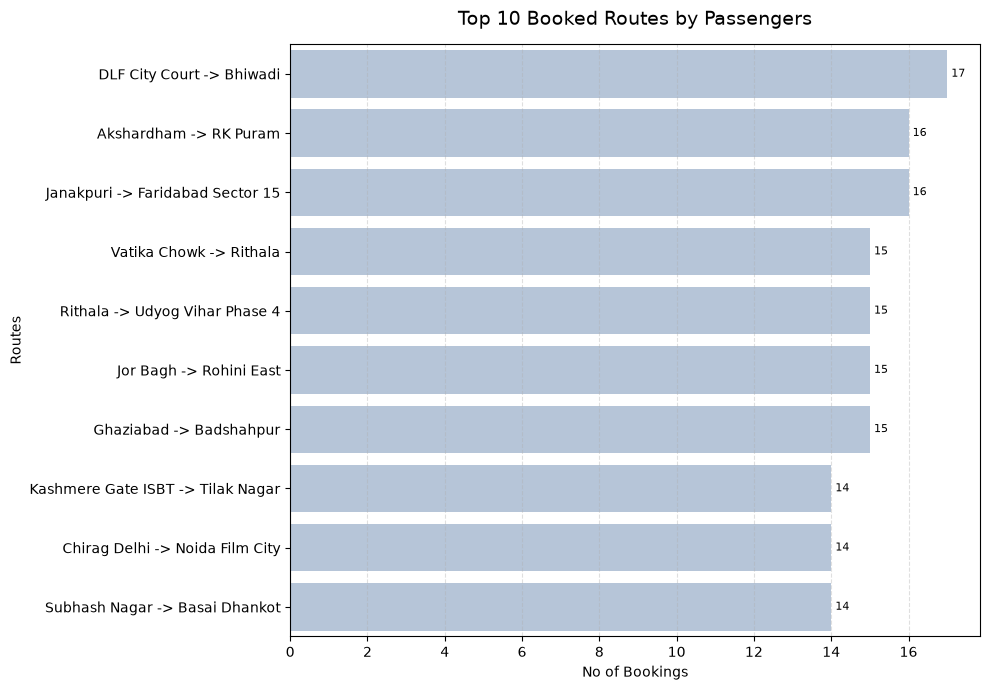

In [18]:
top_n = 10
top_routes = booked_routes.head(top_n).copy()
top_routes['Routes'] = top_routes['Pickup_Location'] + ' -> ' + top_routes['Drop_Location']

plt.figure(figsize=(10, 7))
ax = sns.barplot(data=top_routes, x='Total_Bookings', y='Routes', color='lightsteelblue')

plt.title(f"Top {top_n} Booked Routes by Passengers", fontsize=14, pad=14)
plt.xlabel('No of Bookings')
plt.ylabel('Routes')
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Native Seaborn bar labeling (Blazing fast & automatic)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

plt.tight_layout()
plt.show()

In [19]:
# Most rated routes (drivers's rating)
most_rated_routes = rides_final.groupby(['Pickup Location', 'Drop Location'])['Driver Ratings'].mean().reset_index(name='Ratings').sort_values(by='Ratings', ascending = False)
most_rated_routes.rename(columns={'Pickup Location': 'Pickup_Location', 'Drop Location': 'Drop_Location'}, inplace=True)
print("Most Rated routes (Drivers) :")
for rows in most_rated_routes.head(20).itertuples():
    print(f'{rows.Pickup_Location} ----> {rows.Drop_Location} : {rows.Ratings} ✨')

Most Rated routes (Drivers) :
Jama Masjid ----> Bahadurgarh : 5.0 ✨
Sohna Road ----> Faridabad Sector 15 : 5.0 ✨
GTB Nagar ----> Hero Honda Chowk : 5.0 ✨
Ambience Mall ----> Seelampur : 5.0 ✨
Mundka ----> Seelampur : 5.0 ✨
Keshav Puram ----> Panipat : 5.0 ✨
Rajiv Chowk ----> Noida Extension : 5.0 ✨
Greater Noida ----> Shivaji Park : 5.0 ✨
Sohna Road ----> Sadar Bazar Gurgaon : 5.0 ✨
Ghaziabad ----> Bhiwadi : 5.0 ✨
Dwarka Mor ----> Uttam Nagar : 5.0 ✨
Azadpur ----> Ashok Park Main : 5.0 ✨
Sarojini Nagar ----> Kherki Daula Toll : 5.0 ✨
Noida Extension ----> Patel Chowk : 5.0 ✨
Hauz Rani ----> Sadar Bazar Gurgaon : 5.0 ✨
Pulbangash ----> Yamuna Bank : 5.0 ✨
Dilshad Garden ----> Vidhan Sabha : 5.0 ✨
Civil Lines Gurgaon ----> Rajiv Chowk : 5.0 ✨
Hauz Rani ----> Badshahpur : 5.0 ✨
Jahangirpuri ----> AIIMS : 5.0 ✨


c:\Users\USER\OneDrive\Desktop\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


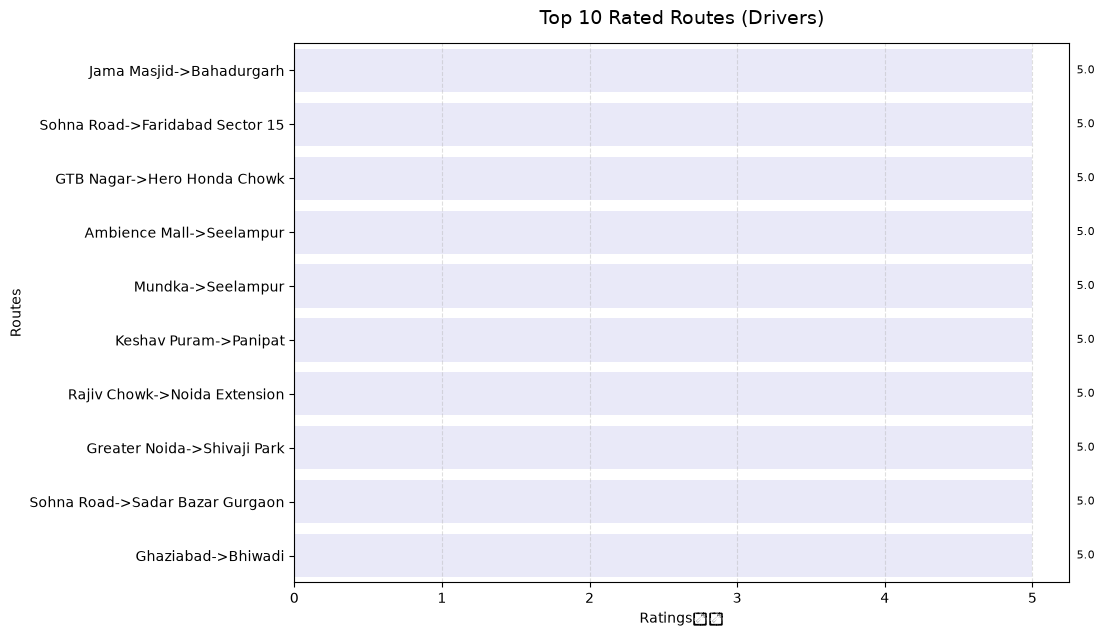

In [20]:
top_n = 10
most_rated = most_rated_routes.head(top_n).copy()
most_rated['Routes'] = most_rated['Pickup_Location'] + '->' + most_rated['Drop_Location']
plt.figure(figsize=(10,7))
sns.barplot(data = most_rated, x = 'Ratings', y = 'Routes', color='lavender')

plt.title(f"Top {top_n} Rated Routes (Drivers)", fontsize = 14, pad = 14)
plt.xlabel('Ratings⭐⭐')
plt.ylabel('Routes')
plt.grid(axis ='x', linestyle='--', alpha=0.4)
for i, v in enumerate(most_rated['Ratings']):
    plt.text(v + 0.3, i,str(v), va = 'center', fontsize = 8)

plt.show()

In [21]:
most_rated_cust = rides_final.groupby(['Pickup Location', 'Drop Location'])['Customer Rating'].mean().reset_index(name='Ratings').sort_values(by='Ratings', ascending = False)
most_rated_cust.rename(columns={'Pickup Location': 'Pickup_Location', 'Drop Location': 'Drop_Location'}, inplace=True)
print("Most Rated routes (Customer) :")
for rows in most_rated_cust.head(20).itertuples():
    print(f'{rows.Pickup_Location} ----> {rows.Drop_Location} : {rows.Ratings} ✨')

Most Rated routes (Customer) :
Civil Lines Gurgaon ----> INA Market : 5.0 ✨
IIT Delhi ----> Kirti Nagar : 5.0 ✨
Gurgaon Sector 29 ----> Ashok Park Main : 5.0 ✨
Kanhaiya Nagar ----> Indirapuram : 5.0 ✨
Noida Sector 18 ----> Pragati Maidan : 5.0 ✨
Ghitorni Village ----> Aya Nagar : 5.0 ✨
Lal Quila ----> New Delhi Railway Station : 5.0 ✨
Palam Vihar ----> Qutub Minar : 5.0 ✨
Laxmi Nagar ----> Ghitorni : 5.0 ✨
Karkarduma ----> Khan Market : 5.0 ✨
Pragati Maidan ----> Mansarovar Park : 5.0 ✨
Qutub Minar ----> Pulbangash : 5.0 ✨
Pulbangash ----> Hauz Rani : 5.0 ✨
Sarai Kale Khan ----> Civil Lines Gurgaon : 5.0 ✨
IGI Airport ----> Kashmere Gate ISBT : 5.0 ✨
Subhash Chowk ----> INA Market : 5.0 ✨
Chhatarpur ----> Rithala : 5.0 ✨
Vasant Kunj ----> Mundka : 5.0 ✨
Lal Quila ----> Narsinghpur : 5.0 ✨
Khandsa ----> DLF Phase 3 : 5.0 ✨


c:\Users\USER\OneDrive\Desktop\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


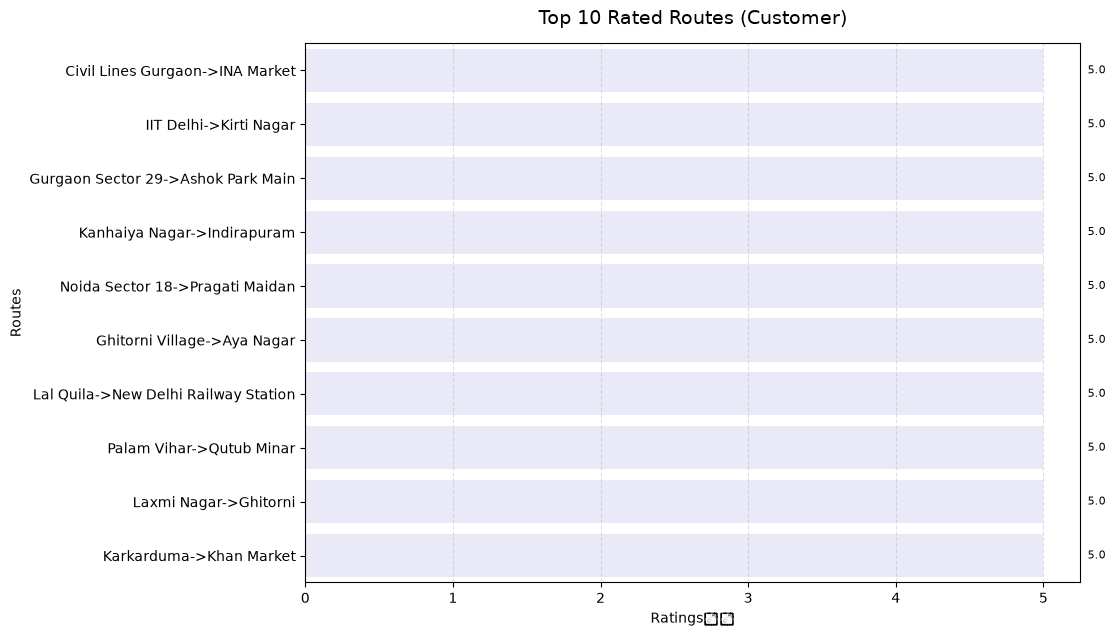

In [22]:
top_n = 10
cust_rated = most_rated_cust.head(top_n).copy()
cust_rated['Routes'] = cust_rated['Pickup_Location'] + '->' + cust_rated['Drop_Location']
plt.figure(figsize=(10,7))
sns.barplot(data = cust_rated, x = 'Ratings', y = 'Routes', color='lavender')

plt.title(f"Top {top_n} Rated Routes (Customer)", fontsize = 14, pad = 14)
plt.xlabel('Ratings⭐⭐')
plt.ylabel('Routes')
plt.grid(axis ='x', linestyle='--', alpha=0.4)
for i, v in enumerate(cust_rated['Ratings']):
    plt.text(v + 0.3, i,str(v), va = 'center', fontsize = 8)

plt.show()

In [23]:
min_trips = 15
route_stats = rides_final.groupby(['Pickup Location', 'Drop Location']).agg(
    Avg_Rating=('Customer Rating', 'mean'),
    Avg_Driv_Rating = ('Driver Ratings', 'mean'),  # Replace with 'Driver_Rating' for drivers
    Total_Bookings=('Booking ID', 'count')
).reset_index()

# 3. Filter for routes meeting the minimum threshold
filtered_routes = route_stats[route_stats['Total_Bookings'] >= min_trips]

# 4. Sort by highest rating, then by highest bookings as a tie-breaker
top_rated_routes = filtered_routes.sort_values(
    by=['Avg_Rating', 'Total_Bookings'], 
    ascending=[False, False]
).head(10)

print(top_rated_routes)

      Pickup Location        Drop Location  Avg_Rating  Avg_Driv_Rating  \
6453        Ghaziabad           Badshahpur    4.686667         4.265262   
476        Akshardham             RK Puram    4.662500         4.211183   
11514       Janakpuri  Faridabad Sector 15    4.625000         4.082309   
12136        Jor Bagh          Rohini East    4.580000         4.156529   
29661    Vatika Chowk              Rithala    4.580000         4.012397   
23616         Rithala  Udyog Vihar Phase 4    4.540000         4.334931   
5065   DLF City Court              Bhiwadi    4.411765         4.171998   

       Total_Bookings  
6453               15  
476                16  
11514              16  
12136              15  
29661              15  
23616              15  
5065               17  


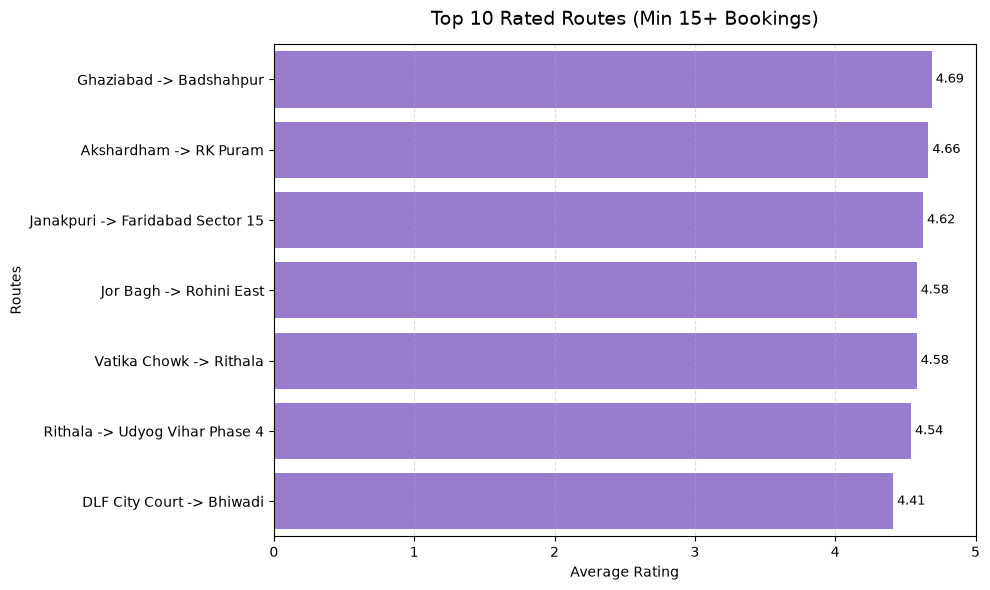

In [24]:
top_rated_routes['Route'] = top_rated_routes['Pickup Location'] + ' -> ' + top_rated_routes['Drop Location']

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=top_rated_routes, 
    x='Avg_Rating', 
    y='Route', 
    color='mediumpurple'
)

plt.title(f'Top 10 Rated Routes (Min {min_trips}+ Bookings)', fontsize=14, pad=14)
plt.xlabel('Average Rating')
plt.ylabel('Routes')
plt.xlim(0, 5)  # Rating scale 0 to 5
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Format labels to 2 decimal places
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

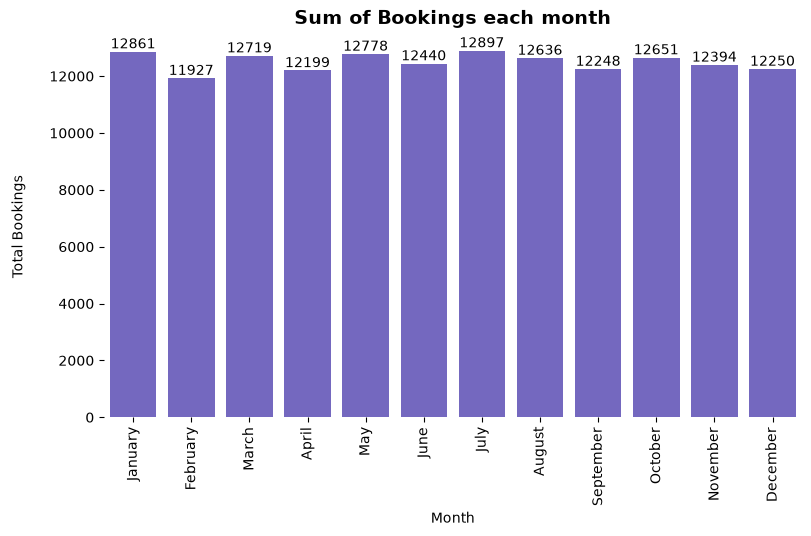

In [25]:
# Distribution of bookings across months
month_stat = rides_final.groupby('Month_Name')['Booking ID'].count().reset_index(name='Total Bookings')
month_dict = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
month_stat.index = pd.CategoricalIndex(month_stat['Month_Name'], categories=month_dict, ordered=True)
month_stat = month_stat.sort_index().reset_index(drop=True)
fig, ax = plt.subplots(figsize = (9,5))
sns.barplot(data=month_stat, x='Month_Name', y = 'Total Bookings', ax = ax, color = 'slateblue')
ax.set_title('Sum of Bookings each month', fontsize = 14, fontweight = 'bold')
ax.set(ylabel='Total Bookings \n', xlabel = 'Month')
ax.tick_params(axis='x', rotation = 90.5)
sns.despine(left=True, right=True, bottom=True, top=True)
for bars in ax.containers:
    ax.bar_label(bars, label_type='edge')
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_13500\2134209219.py:4: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  season_stats.index = pd.CategoricalIndex(season_stats['Season'], categories=season, ordered=True)


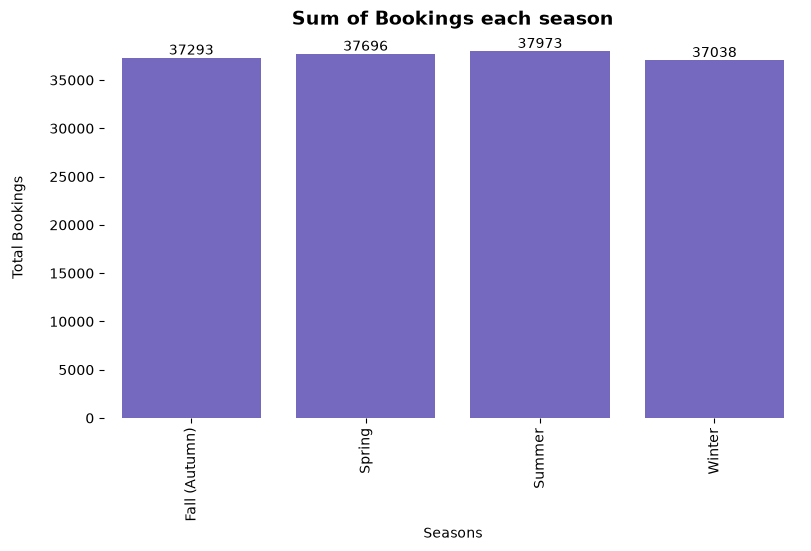

In [26]:
# Distribution of Bookings each season
season_stats = rides_final.groupby('Season')['Booking ID'].count().reset_index(name = "Total Bookings")
season = ['Spring', 'Summer', 'Autumn', 'Winter']
season_stats.index = pd.CategoricalIndex(season_stats['Season'], categories=season, ordered=True)
season_stats = season_stats.sort_index().reset_index(drop = True)
fig, ax = plt.subplots(figsize = (9,5))
sns.barplot(data=season_stats, x='Season', y = 'Total Bookings', ax = ax, color = 'slateblue')
ax.set_title('Sum of Bookings each season', fontsize = 14, fontweight = 'bold')
ax.set(ylabel='Total Bookings \n', xlabel = 'Seasons')
ax.tick_params(axis='x', rotation = 90.5)
sns.despine(left=True, right=True, bottom=True, top=True)
for bars in ax.containers:
    ax.bar_label(bars, label_type='edge')
plt.show()

In [27]:
# 1. Flag successful bookings (1 if successful, 0 otherwise)
rides_final['Is_Success'] = (rides_final['Booking Status'] == 'Completed').astype(int)

# 2. Resample daily to get Total and Successful bookings
day_bookings = rides_final.set_index('Date').resample('1D').agg(
    Total_Bookings=('Booking ID', 'count'),
    Successful_Bookings=('Is_Success', 'sum')
).reset_index()

# 3. Add Day of Week and calculate averages grouped by Day
day_bookings['Day'] = day_bookings['Date'].dt.day_name()

avg_weekly = day_bookings.groupby('Day')[['Total_Bookings', 'Successful_Bookings']].mean().reset_index()

# 4. Calculate Success Percentage
avg_weekly['Success Rate (%)'] = (avg_weekly['Successful_Bookings'] / avg_weekly['Total_Bookings']) * 100

# 5. Order days chronologically
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
avg_weekly['Day'] = pd.Categorical(avg_weekly['Day'], categories=day_order, ordered=True)
avg_weekly = avg_weekly.sort_values('Day').reset_index(drop=True)

print(avg_weekly[['Day', 'Total_Bookings', 'Successful_Bookings', 'Success Rate (%)']])

         Day  Total_Bookings  Successful_Bookings  Success Rate (%)
0     Monday      408.377358           251.283019         61.532064
1    Tuesday      411.365385           253.288462         61.572624
2  Wednesday      411.788462           255.692308         62.093121
3   Thursday      407.980769           253.961538         62.248409
4     Friday      411.480769           254.865385         61.938590
5   Saturday      414.269231           258.500000         62.399034
6     Sunday      411.500000           256.038462         62.220768


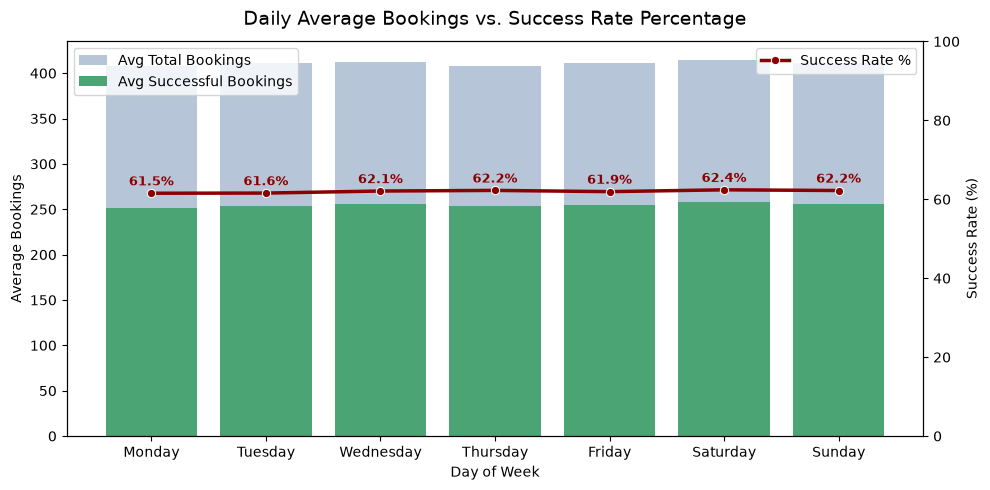

In [28]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar plot for Total vs Successful volume
sns.barplot(data=avg_weekly, x='Day', y='Total_Bookings', color='lightsteelblue', ax=ax1, label='Avg Total Bookings')
sns.barplot(data=avg_weekly, x='Day', y='Successful_Bookings', color='mediumseagreen', ax=ax1, label='Avg Successful Bookings')

ax1.set_ylabel('Average Bookings')
ax1.set_xlabel('Day of Week')
ax1.legend(loc='upper left')

# Line plot for Success Percentage on secondary axis
ax2 = ax1.twinx()
sns.lineplot(data=avg_weekly, x='Day', y='Success Rate (%)', color='darkred', marker='o', linewidth=2.5, ax=ax2, label='Success Rate %')

ax2.set_ylabel('Success Rate (%)')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Add data labels for percentage
for i, rate in enumerate(avg_weekly['Success Rate (%)']):
    ax2.text(i, rate + 2, f"{rate:.1f}%", ha='center', color='darkred', fontweight='bold', fontsize=9)

plt.title('Daily Average Bookings vs. Success Rate Percentage', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

In [29]:
# 2. Resample daily to get Total and Successful bookings
month_bookings = rides_final.set_index('Date').resample('ME').agg(
    Total_Bookings=('Booking ID', 'count'),
    Successful_Bookings=('Is_Success', 'sum')
).reset_index()

# 3. Add Day of Week and calculate averages grouped by Day
month_bookings['MONTH'] = month_bookings['Date'].dt.month_name()

avg_monthly = month_bookings.groupby('MONTH')[['Total_Bookings', 'Successful_Bookings']].mean().reset_index()

# 4. Calculate Success Percentage
avg_monthly['Success Rate (%)'] = (avg_monthly['Successful_Bookings'] / avg_monthly['Total_Bookings']) * 100

# 5. Order days chronologically
month_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
avg_monthly['MONTH'] = pd.Categorical(avg_monthly['MONTH'], categories=month_dict, ordered=True)
avg_monthly = avg_monthly.sort_values('MONTH').reset_index(drop=True)

print(avg_monthly[['MONTH', 'Total_Bookings', 'Successful_Bookings', 'Success Rate (%)']])

        MONTH  Total_Bookings  Successful_Bookings  Success Rate (%)
0     January         12861.0               7951.0         61.822564
1    February         11927.0               7368.0         61.775803
2       March         12719.0               7954.0         62.536363
3       April         12199.0               7632.0         62.562505
4         May         12778.0               7905.0         61.864141
5        June         12440.0               7757.0         62.355305
6        July         12897.0               7926.0         61.456153
7      August         12636.0               7780.0         61.570117
8   September         12248.0               7542.0         61.577400
9     October         12651.0               7905.0         62.485179
10   November         12394.0               7659.0         61.796030
11   December         12250.0               7621.0         62.212245


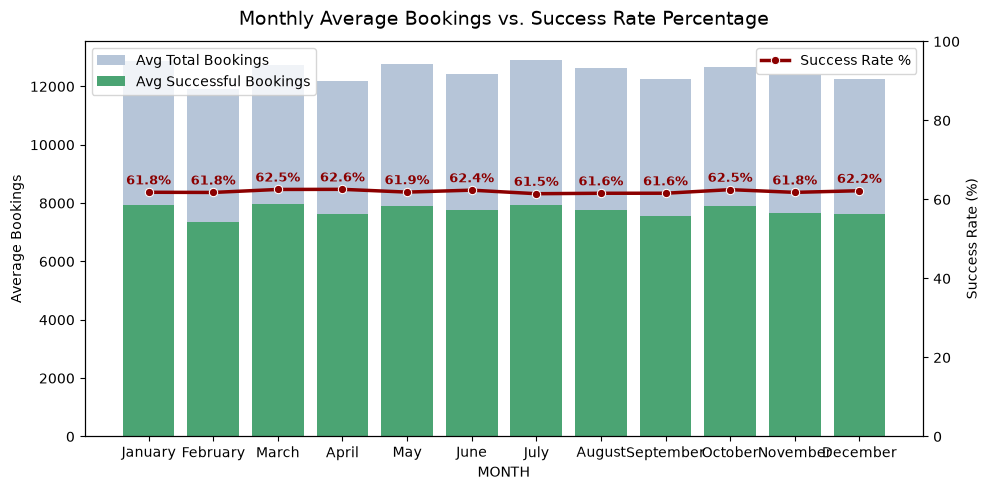

In [30]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar plot for Total vs Successful volume
sns.barplot(data=avg_monthly, x='MONTH', y='Total_Bookings', color='lightsteelblue', ax=ax1, label='Avg Total Bookings')
sns.barplot(data=avg_monthly, x='MONTH', y='Successful_Bookings', color='mediumseagreen', ax=ax1, label='Avg Successful Bookings')

ax1.set_ylabel('Average Bookings')
ax1.set_xlabel('MONTH')
ax1.legend(loc='upper left')

# Line plot for Success Percentage on secondary axis
ax2 = ax1.twinx()
sns.lineplot(data=avg_monthly, x='MONTH', y='Success Rate (%)', color='darkred', marker='o', linewidth=2.5, ax=ax2, label='Success Rate %')

ax2.set_ylabel('Success Rate (%)')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Add data labels for percentage
for i, rate in enumerate(avg_monthly['Success Rate (%)']):
    ax2.text(i, rate + 2, f"{rate:.1f}%", ha='center', color='darkred', fontweight='bold', fontsize=9)

plt.title('Monthly Average Bookings vs. Success Rate Percentage', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

In [31]:

success_routes_stats = rides_final.groupby(['Pickup Location', 'Drop Location']).agg(
    Total_Bookings = ('Booking ID', 'count'),
    Successful_Bookings = ('Is_Success', 'sum')
).reset_index()

success_routes_stats['Success Rate (%)'] = (success_routes_stats['Successful_Bookings'] / success_routes_stats['Total_Bookings'])
print(success_routes_stats[['Pickup Location', 'Drop Location', 'Successful_Bookings', 'Success Rate (%)']])

      Pickup Location     Drop Location  Successful_Bookings  Success Rate (%)
0               AIIMS      Adarsh Nagar                    1          0.500000
1               AIIMS        Akshardham                    2          0.666667
2               AIIMS     Ambience Mall                    2          0.333333
3               AIIMS       Anand Vihar                    2          0.666667
4               AIIMS  Anand Vihar ISBT                    1          0.200000
...               ...               ...                  ...               ...
30559     Yamuna Bank      Vatika Chowk                    6          0.750000
30560     Yamuna Bank      Vidhan Sabha                    4          1.000000
30561     Yamuna Bank        Vinobapuri                    2          1.000000
30562     Yamuna Bank   Vishwavidyalaya                    5          0.833333
30563     Yamuna Bank           Welcome                    2          0.666667

[30564 rows x 4 columns]


In [32]:
min_trips = 15
succes_rate_routes = [success_routes_stats['Total_Bookings'] >= min_trips]

# 4. Sort by highest rating, then by highest bookings as a tie-breaker
succes_rate_routes = success_routes_stats.sort_values(
    by=['Successful_Bookings', 'Total_Bookings'], 
    ascending=[False, False]
).head(10)

succes_rate_routes.rename(columns={
    'Pickup Location' : 'Pickup_Location',
    'Drop Location' :'Drop_Location',
    'Success Rate (%)' : 'Sucess_Rate_(%)'
}, inplace=True)

succes_rate_routes['Routes'] = succes_rate_routes['Pickup_Location'] + '--->' + succes_rate_routes['Drop_Location']


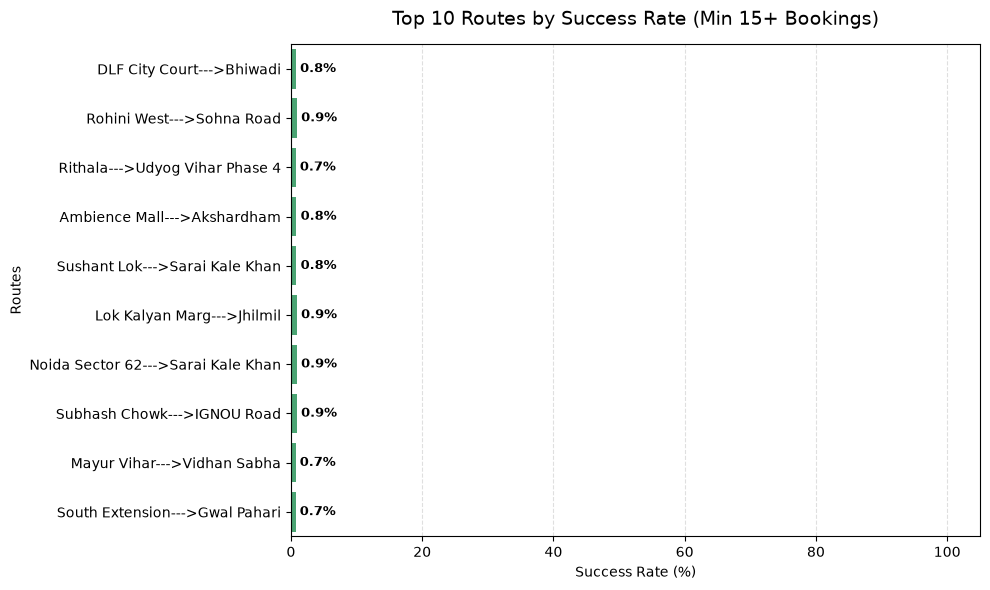

In [33]:
fig, plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=succes_rate_routes,
    x='Sucess_Rate_(%)',
    y='Routes',
    color='mediumseagreen'
)

plt.title(f'Top 10 Routes by Success Rate (Min {min_trips}+ Bookings)', fontsize=14, pad=14)
plt.xlabel('Success Rate (%)')
plt.ylabel('Routes')
plt.xlim(0, 105)  # Prevents percentage labels from clipping off-screen
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Vectorized percentage labels directly on bars
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()



In [34]:
rides_final.columns

Index(['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID',
       'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT',
       'Avg CTAT', 'Cancelled Rides by Customer',
       'Reason for cancelling by Customer', 'Cancelled Rides by Driver',
       'Driver Cancellation Reason', 'Incomplete Rides',
       'Incomplete Rides Reason', 'Booking Value', 'Ride Distance',
       'Driver Ratings', 'Customer Rating', 'Payment Method', 'Year',
       'Month_Name', 'Day_Name', 'Is_Weekend', 'Hour', 'Revenue_per_km',
       'Time_of_day', 'Season', 'Is_Success'],
      dtype='str')

In [35]:
# Top Revenue generating routes 
min_trips = 10
perf_routes = rides_final.groupby(['Pickup Location', 'Drop Location']).agg(Revenue = ('Revenue_per_km', 'sum'),
                                                                          Total_Bookings = ('Booking ID', 'count')).reset_index()
perf_filtered_routes = perf_routes[perf_routes['Total_Bookings'] >= min_trips]

# 4. Sort by highest rating, then by highest bookings as a tie-breaker
top_perf_routes = perf_filtered_routes.sort_values(
    by=['Revenue', 'Total_Bookings'], 
    ascending=[False, False]
).head(10)

print(top_perf_routes)

      Pickup Location        Drop Location      Revenue  Total_Bookings
17571         Munirka          Bahadurgarh  1652.728417              11
10079     IMT Manesar  Udyog Vihar Phase 4  1294.270189              10
5164   DLF City Court        Paschim Vihar  1153.599629              10
22565        RK Puram        Subhash Nagar  1088.842349              10
23620         Rithala         Vatika Chowk  1037.733687              11
16676          Meerut         Udyog Bhawan   984.165537              11
28756     Udyog Vihar      Mansarovar Park   983.451493              11
8513      Gwal Pahari          Udyog Vihar   926.420174              10
21920      Pulbangash          DLF Phase 3   907.014503              10
8725        Hauz Rani            Cyber Hub   904.272929              10


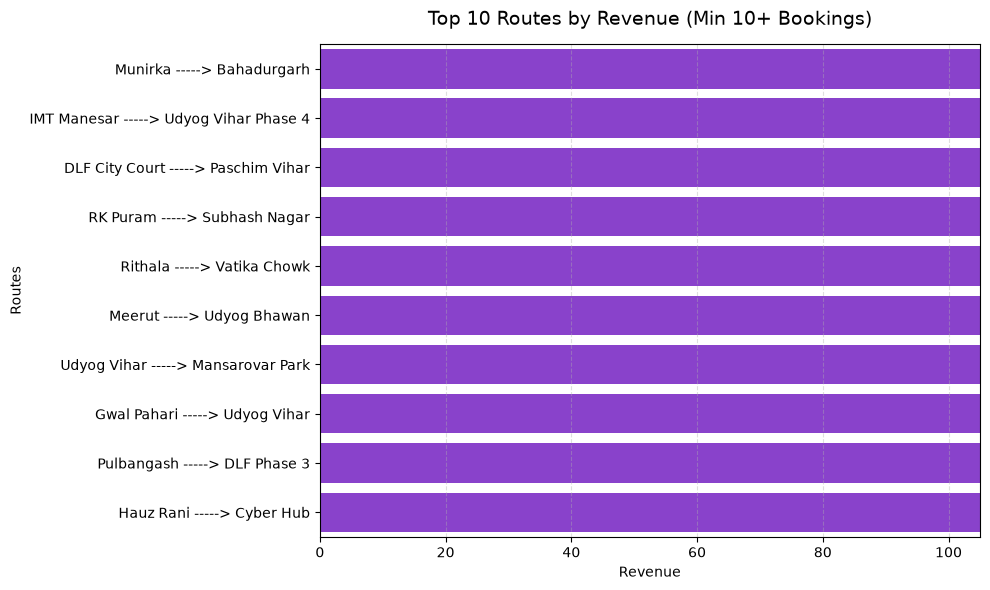

In [36]:
top_perf_routes['Routes'] = top_perf_routes['Pickup Location'] + ' -----> ' + top_perf_routes['Drop Location']
top_rated_routes.rename(columns={
    'Pickup Location' : 'Pickup_Location',
    'Drop Location' : 'Drop_Location'
}, inplace=True)

fig, plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=top_perf_routes,
    x='Revenue',
    y='Routes',
    color='blueviolet'
)

plt.title(f'Top 10 Routes by Revenue (Min {min_trips}+ Bookings)', fontsize=14, pad=14)
plt.xlabel('Revenue')
plt.ylabel('Routes')
plt.xlim(0, 105)  # Prevents percentage labels from clipping off-screen
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Vectorized percentage labels directly on bars
for bars in ax.containers:
    ax.bar_label(bars, label_type='edge')

plt.tight_layout()
plt.show()

In [37]:
# Ride Volume per vehicle 
ride_volume = rides_final.groupby('Vehicle Type').agg(Total_Bookings = ('Booking ID', 'count'),
                                                      Successful_Bookings = ('Is_Success', 'sum')).reset_index()
ride_volume['Success Rate (%)'] = (ride_volume['Successful_Bookings'] / ride_volume['Total_Bookings']) * 100
print(ride_volume[['Vehicle Type','Total_Bookings' ,'Successful_Bookings', 'Success Rate (%)']])

    Vehicle Type  Total_Bookings  Successful_Bookings  Success Rate (%)
0           Auto           37419                23155         61.880328
1           Bike           22517                14034         62.326242
2        Go Mini           29806                18549         62.232436
3       Go Sedan           27141                16676         61.442099
4  Premier Sedan           18111                11252         62.127989
5        Uber XL            4449                 2783         62.553383
6          eBike           10557                 6551         62.053614


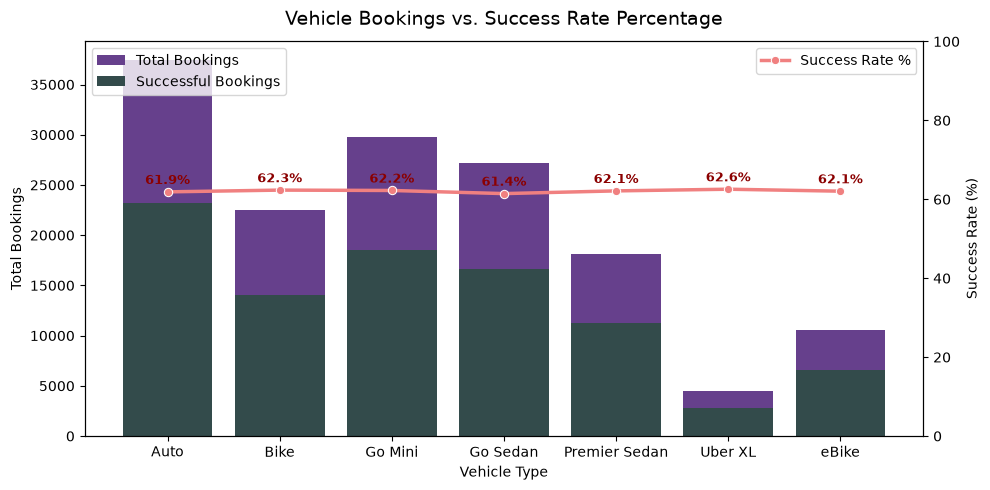

In [38]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar plot for Total vs Successful volume
sns.barplot(data=ride_volume, x='Vehicle Type', y='Total_Bookings', color='rebeccapurple', ax=ax1, label='Total Bookings')
sns.barplot(data=ride_volume, x='Vehicle Type', y='Successful_Bookings', color='darkslategrey', ax=ax1, label='Successful Bookings')

ax1.set_ylabel('Total Bookings')
ax1.set_xlabel('Vehicle Type')
ax1.legend(loc='upper left')

# Line plot for Success Percentage on secondary axis
ax2 = ax1.twinx()
sns.lineplot(data=ride_volume, x='Vehicle Type', y='Success Rate (%)', color='lightcoral', marker='o', linewidth=2.5, ax=ax2, label='Success Rate %')

ax2.set_ylabel('Success Rate (%)')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Add data labels for percentage
for i, rate in enumerate(ride_volume['Success Rate (%)']):
    ax2.text(i, rate + 2, f"{rate:.1f}%", ha='center', color='darkred', fontweight='bold', fontsize=9)

plt.title('Vehicle Bookings vs. Success Rate Percentage', fontsize=14, pad=12)
plt.tight_layout()
plt.show()